## Labels vs. Scale: Breaking Even on Banking77 with Encoders and Decoders

#### Results

This notebook only **displays** results. All logic lives in `scripts/evaluation.py`, which every model script also uses, so the files are written, checked and scored the same way everywhere.

Every model run writes one prediction CSV per split to `results/`, following `results/PREDICTION_FORMAT.md`. A file that breaks the format stops the scoring with a list of every problem found.

**Ground rules**
- Tune on `val`, report on `test`.
- An unmatched decoder answer (`-1`) counts as wrong. It is never dropped.

#### Setup

In [ ]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import pandas as pd

# Find the project root (the folder that contains scripts/download_data.py), wherever the kernel starts
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / "scripts" / "download_data.py").exists()), cwd)

# Make scripts/ importable, then load the shared evaluation module

sys.path.insert(0, str(ROOT / "scripts"))
import evaluation as ev

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

REPORTS = ev.ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

print("Prediction files in results/:", len(list(ev.RESULTS.glob("*.csv"))))

def natural_order(summary):
    # For display only: sort by model, then by budget size (k1, k3, ..., full) instead of alphabetically
    order = [b for b in ev.BUDGETS if b in summary["budget"].unique()]
    out = summary.copy()
    out["budget"] = pd.Categorical(out["budget"], categories=order, ordered=True)
    return out.sort_values(["model", "budget"]).reset_index(drop=True)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Prediction files in results/: 255


#### Validation scores
The same scoring on the validation split. Use these to tune, and use the test scores above only for the final numbers.

In [41]:
val_summary = ev.summarize(ev.score_all("val"))
natural_order(val_summary).round(3)

,model,type,budget,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,n_seeds
0,majority,baseline,k1,0.013,0.000,0.000,0.000,3
1,majority,baseline,k3,0.013,0.000,0.000,0.000,3
2,majority,baseline,k5,0.013,0.000,0.000,0.000,3
3,majority,baseline,k10,0.013,0.000,0.000,0.000,3
4,majority,baseline,k20,0.013,0.000,0.000,0.000,3
5,majority,baseline,k30,0.013,0.000,0.000,0.000,3
6,majority,baseline,p50,0.013,0.000,0.000,0.000,3
7,majority,baseline,full,0.013,0.000,0.000,0.000,3
8,modernbert,encoder,k1,0.074,0.033,0.057,0.030,3
9,modernbert,encoder,k3,0.179,0.091,0.149,0.095,3


#### Score every run
`score_all` loads each `*_test.csv`, checks it against the format, and scores it. `summarize` then gives the mean and standard deviation across seeds for each model and budget.

In [ ]:
# One row per run, then mean and standard deviation across seeds
scores = ev.score_all("test")
summary = natural_order(ev.summarize(scores)).round(3)

# Save next to the prediction files. ev.RESULTS is the project's results folder, so this works from any notebook folder
summary.to_csv(REPORTS / "summary_test.csv", index=False)
print("Saved:", REPORTS / "summary_test.csv")

summary


Saved: /Users/chandu/Desktop/Term3-Fall2026/266-NLP/Final Project/DATASCI266-Banking77-Encoder-vs-Decoder/results/summary_test.csv


,model,type,budget,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,n_seeds
0,majority,baseline,k1,0.013,0.000,0.000,0.000,3
1,majority,baseline,k3,0.013,0.000,0.000,0.000,3
2,majority,baseline,k5,0.013,0.000,0.000,0.000,3
3,majority,baseline,k10,0.013,0.000,0.000,0.000,3
4,majority,baseline,k20,0.013,0.000,0.000,0.000,3
5,majority,baseline,k30,0.013,0.000,0.000,0.000,3
6,majority,baseline,p50,0.013,0.000,0.000,0.000,3
7,majority,baseline,full,0.013,0.000,0.000,0.000,3
8,modernbert,encoder,k1,0.083,0.040,0.065,0.039,3
9,modernbert,encoder,k3,0.177,0.103,0.146,0.110,3


### Are all runs there?
Seeds found for each model and budget. A missing run shows as `NaN`; zero-shot models should have exactly 1 seed.

In [44]:
# Columns in budget order, only the budgets that exist
order = [b for b in ev.BUDGETS if b in summary["budget"].unique()]
summary.pivot(index="model", columns="budget", values="n_seeds")[order]

budget,zeroshot,k1,k3,k5,k10,k20,k30,p50,full
model,,,,,,,,,
majority,NaN,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0
modernbert,NaN,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0
modernbert_min300,NaN,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0
modernbert_min600,NaN,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN
qwen_sft,NaN,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0
qwen_zeroshot,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tfidf_lr,NaN,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0


#### Learning curves
Score against the number of training examples (log scale). Where the encoder and decoder lines cross is the break-even point. The shaded band is one standard deviation across seeds. Zero-shot models are flat dashed lines. The figures are also saved to `reports/figures/`.

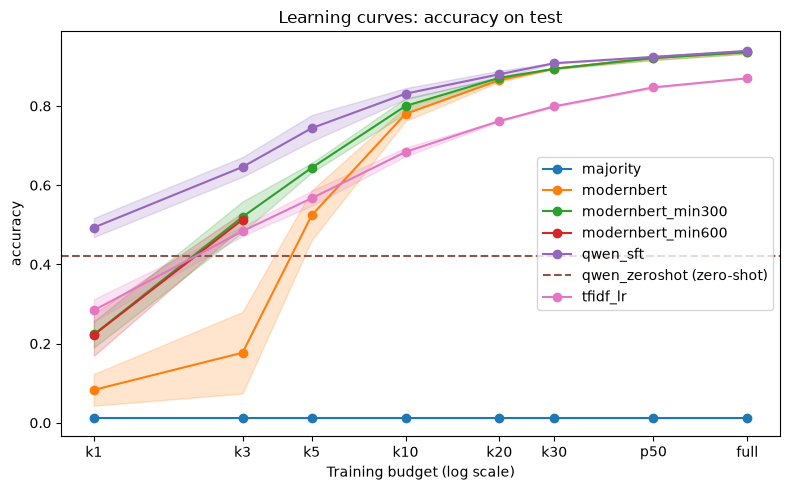

In [45]:
# Accuracy (primary metric)
ev.plot_learning_curve(summary, "accuracy", save_to=FIG / "learning_curve_accuracy.png")

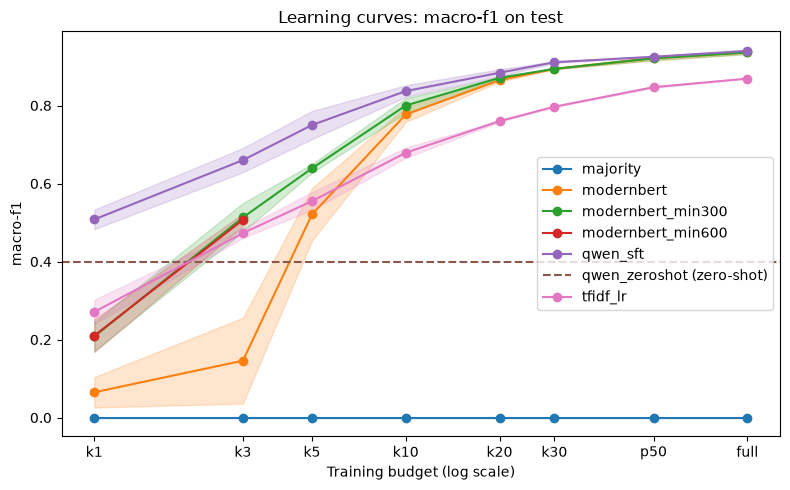

In [51]:
# Macro-F1 (secondary metric)
ev.plot_learning_curve(summary, "macro_f1", save_to=FIG / "learning_curve_macro_f1.png")

#### Look inside one run
Change `RUN` to any file in `results/`. The first table shows the ten weakest intents. The second shows the most frequent mistakes (an unmatched decoder answer appears as `unmatched`).

In [48]:
# Any prediction file in results/

# RUN = "majority_full_seed0_test.csv"
# RUN = "tfidf_lr_full_seed0_test.csv"
RUN = "modernbert_full_seed0_test.csv"

df = ev.load_predictions(ev.RESULTS / RUN)
print("Run:", RUN)
print("Scores:", ev.score(df))

# The ten intents with the lowest F1
ev.per_intent(df).sort_values("f1").head(10)

Run: modernbert_full_seed0_test.csv
Scores: {'accuracy': 0.938961038961039, 'macro_f1': 0.9388945721018275}


,intent,precision,recall,f1,support
5,balance_not_updated_after_bank_transfer,0.794872,0.775,0.784810,40
61,top_up_reverted,0.850000,0.850,0.850000,40
66,transfer_not_received_by_recipient,0.850000,0.850,0.850000,40
62,topping_up_by_card,0.914286,0.800,0.853333,40
48,pending_transfer,0.891892,0.825,0.857143,40
11,card_arrival,0.818182,0.900,0.857143,40
59,top_up_failed,0.853659,0.875,0.864198,40
27,declined_transfer,1.000000,0.775,0.873239,40
41,lost_or_stolen_card,0.918919,0.850,0.883117,40
54,supported_cards_and_currencies,0.826087,0.950,0.883721,40


In [50]:
# The ten most frequent mistakes: true intent -> predicted intent
ev.top_confusions(df, 10)

,true,predicted,count
0,balance_not_updated_after_bank_transfer,transfer_not_received_by_recipient,4
1,card_delivery_estimate,card_arrival,4
2,visa_or_mastercard,supported_cards_and_currencies,3
3,exchange_charge,exchange_rate,3
4,transfer_timing,balance_not_updated_after_bank_transfer,3
5,card_arrival,card_delivery_estimate,3
6,top_up_failed,top_up_reverted,3
7,card_payment_not_recognised,compromised_card,3
8,exchange_via_app,fiat_currency_support,3
9,why_verify_identity,verify_my_identity,3
